In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("SmartBiz AI Project Started Successfully!")

SmartBiz AI Project Started Successfully!


In [ ]:
dataset = fetch_ucirepo(id=468)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
print("Dataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  T

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Column Names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [ ]:
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate rows before cleaning:")
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numerical values with median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
cat_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in cat_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("\nData Cleaning Completed!")
print("Clean Dataset Shape:", df.shape)
print("Missing Values After Cleaning:", df.isnull().sum().sum())
print("Duplicate Rows After Cleaning:", df.duplicated().sum())

Missing values before cleaning:
0

Duplicate rows before cleaning:
125

Data Cleaning Completed!
Clean Dataset Shape: (12205, 18)
Missing Values After Cleaning: 0
Duplicate Rows After Cleaning: 0


Purchase Distribution:


,count
Revenue,
False,10297
True,1908



Purchase Percentage:


,proportion
Revenue,
False,84.37
True,15.63


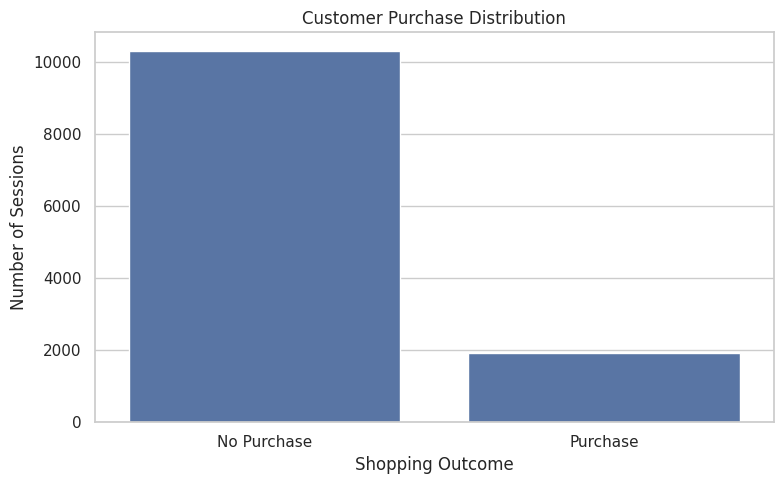

In [ ]:
print("Purchase Distribution:")
display(df["Revenue"].value_counts())

print("\nPurchase Percentage:")
display(
    (df["Revenue"].value_counts(normalize=True) * 100).round(2)
)

purchase_counts = df["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=["No Purchase", "Purchase"],
    y=purchase_counts.values
)
plt.title("Customer Purchase Distribution")
plt.xlabel("Shopping Outcome")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

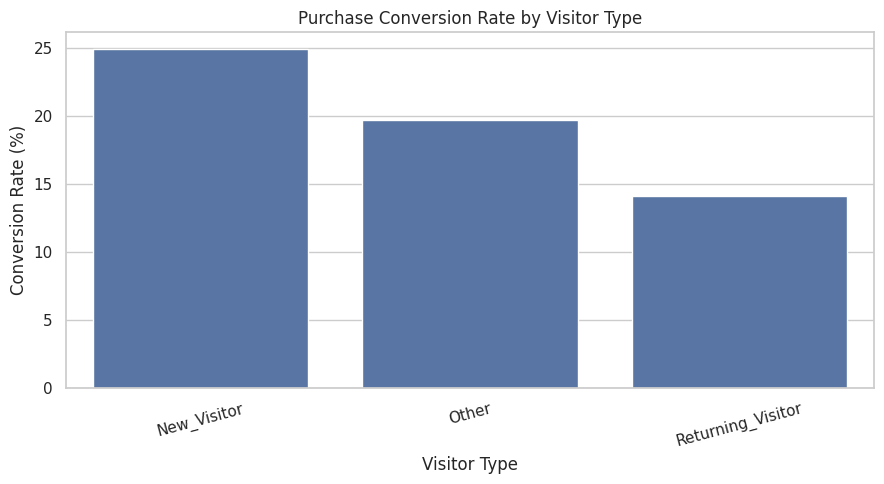

,Revenue
VisitorType,
New_Visitor,24.93
Other,19.75
Returning_Visitor,14.09


In [ ]:
visitor_analysis = df.groupby(
    "VisitorType", observed=False
)["Revenue"].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=visitor_analysis.index,
    y=visitor_analysis.values
)
plt.title("Purchase Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(visitor_analysis.round(2))

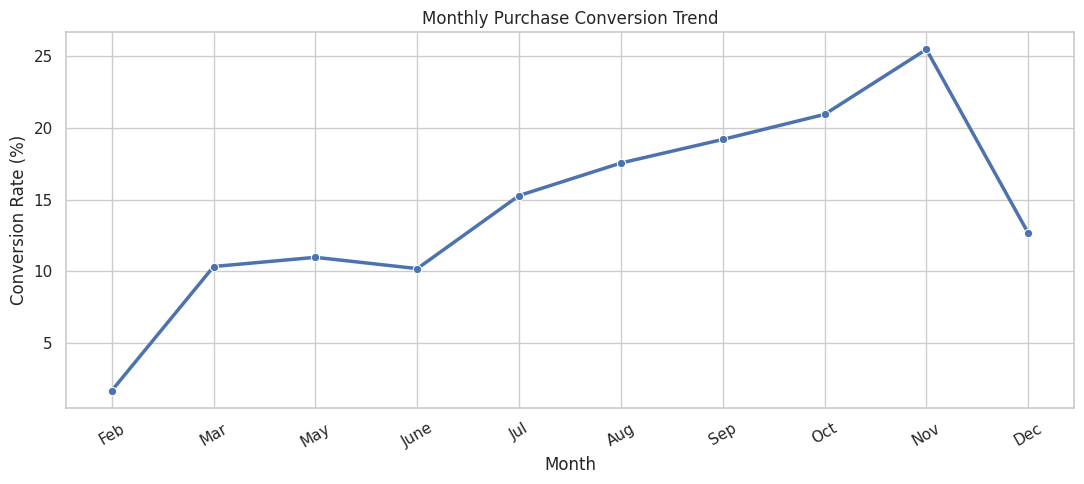

In [ ]:
monthly_analysis = df.groupby(
    "Month", observed=False
)["Revenue"].mean().mul(100)

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_analysis = monthly_analysis.reindex(
    [m for m in month_order if m in monthly_analysis.index]
)

plt.figure(figsize=(11, 5))
sns.lineplot(
    x=monthly_analysis.index,
    y=monthly_analysis.values,
    marker="o",
    linewidth=2.5
)
plt.title("Monthly Purchase Conversion Trend")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

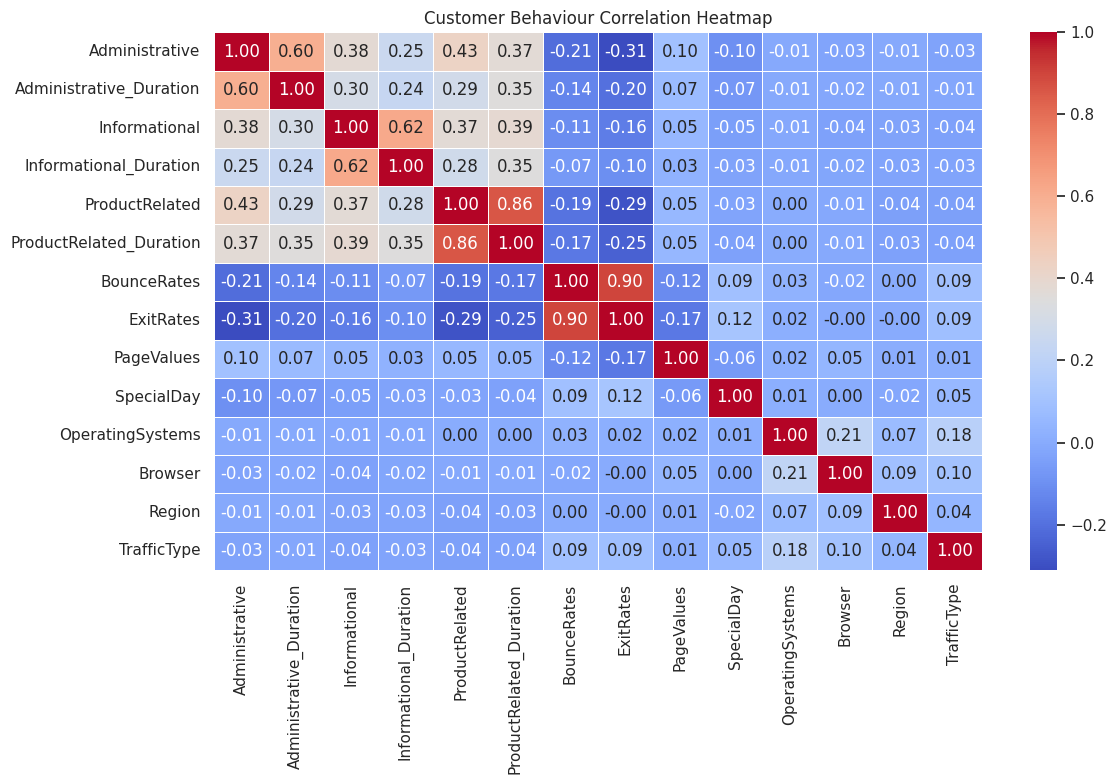

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Customer Behaviour Correlation Heatmap")
plt.tight_layout()
plt.show()

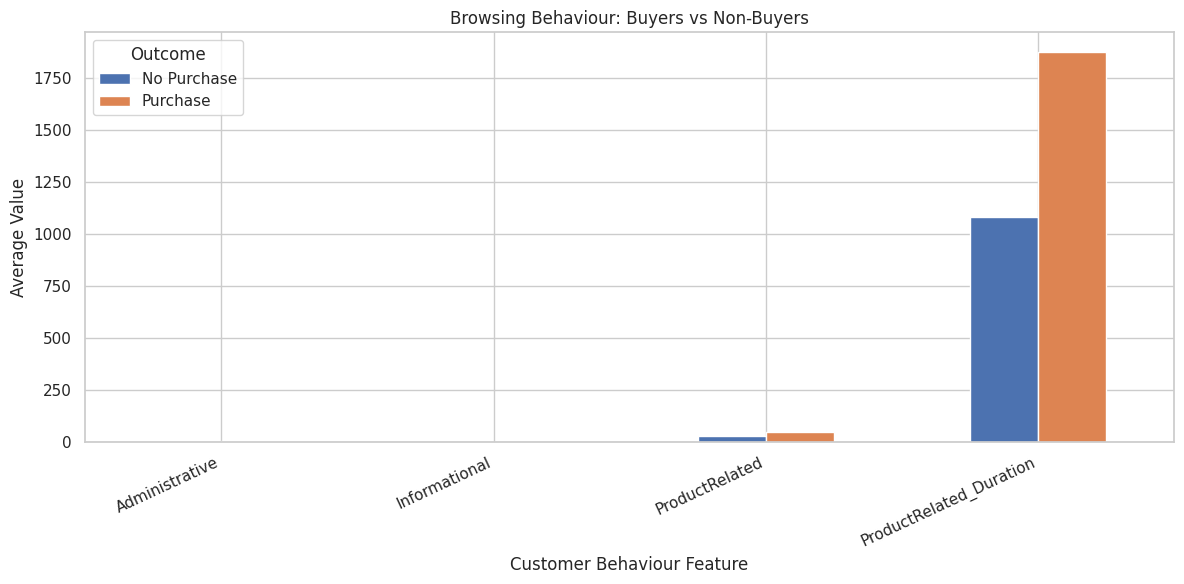

,No Purchase,Purchase
Administrative,2.14,3.39
Informational,0.46,0.79
ProductRelated,29.05,48.21
ProductRelated_Duration,1082.98,1876.21


In [ ]:
features_to_compare = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "ProductRelated_Duration"
]

comparison = df.groupby("Revenue")[
    features_to_compare
].mean().T

comparison.columns = ["No Purchase", "Purchase"]

comparison.plot(kind="bar", figsize=(12, 6))
plt.title("Browsing Behaviour: Buyers vs Non-Buyers")
plt.xlabel("Customer Behaviour Feature")
plt.ylabel("Average Value")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

display(comparison.round(2))

In [ ]:
X = df.drop(columns=["Revenue"]).copy()
y = df["Revenue"].astype(int)

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Handle any remaining infinite or missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training rows: 9764
Testing rows: 2441
Number of features: 26


In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    min_samples_leaf=2,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    )
)

Accuracy: 0.9013
ROC-AUC: 0.9295

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.94      0.95      0.94      2059
    Purchase       0.69      0.66      0.68       382

    accuracy                           0.90      2441
   macro avg       0.82      0.81      0.81      2441
weighted avg       0.90      0.90      0.90      2441



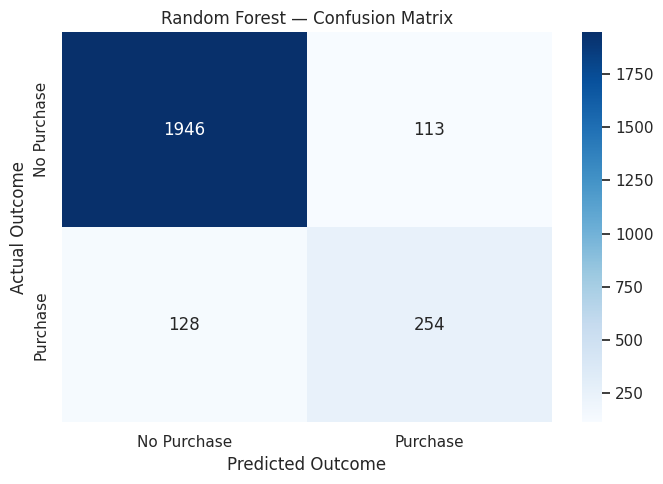

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

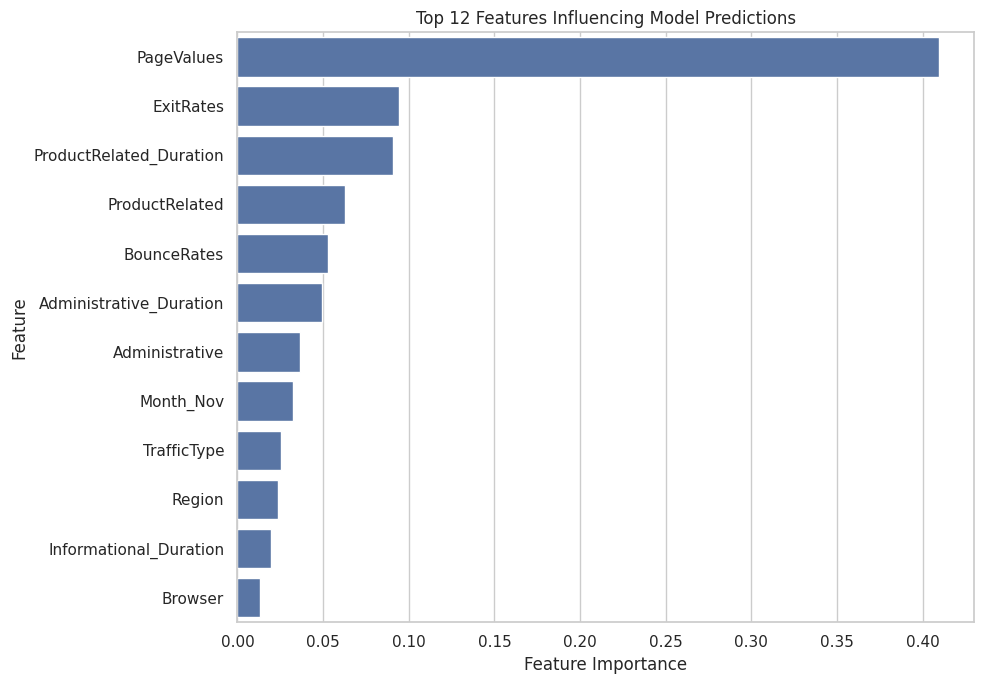

,Importance
PageValues,0.409428
ExitRates,0.094241
ProductRelated_Duration,0.090657
ProductRelated,0.062761
BounceRates,0.052622
Administrative_Duration,0.049170
Administrative,0.036482
Month_Nov,0.032315
TrafficType,0.025391
Region,0.023612


In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 7))
sns.barplot(
    x=importance.values,
    y=importance.index
)
plt.title("Top 12 Features Influencing Model Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance.to_frame("Importance"))

In [ ]:
total_sessions = len(df)
total_purchases = int(df["Revenue"].sum())
total_non_purchases = total_sessions - total_purchases
conversion_rate = (total_purchases / total_sessions) * 100

print("=" * 55)
print("       SMARTBIZ AI — EXECUTIVE REPORT")
print("=" * 55)

print(f"Total Sessions: {total_sessions:,}")
print(f"Purchase Sessions: {total_purchases:,}")
print(f"Non-Purchase Sessions: {total_non_purchases:,}")
print(f"Overall Conversion Rate: {conversion_rate:.2f}%")

print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Model ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

print("\nTop 5 Important Features:")
print(importance.head(5).to_string())

print("\nBusiness Recommendations:")
print("1. Investigate browsing patterns linked with purchases.")
print("2. Compare conversion rates across visitor types.")
print("3. Identify pages associated with low conversion.")
print("4. Test website improvements using controlled experiments.")
print("5. Evaluate ML performance using multiple metrics.")

print("=" * 55)

       SMARTBIZ AI — EXECUTIVE REPORT
Total Sessions: 12,205
Purchase Sessions: 1,908
Non-Purchase Sessions: 10,297
Overall Conversion Rate: 15.63%
Model Accuracy: 90.13%
Model ROC-AUC: 0.930

Top 5 Important Features:
PageValues                 0.409428
ExitRates                  0.094241
ProductRelated_Duration    0.090657
ProductRelated             0.062761
BounceRates                0.052622

Business Recommendations:
1. Investigate browsing patterns linked with purchases.
2. Compare conversion rates across visitor types.
3. Identify pages associated with low conversion.
4. Test website improvements using controlled experiments.
5. Evaluate ML performance using multiple metrics.


In [ ]:
df.to_csv("SmartBiz_Cleaned_Data.csv", index=False)

importance.to_csv("SmartBiz_Feature_Importance.csv")

report = pd.DataFrame({
    "Metric": [
        "Total Sessions",
        "Purchase Sessions",
        "Non-Purchase Sessions",
        "Conversion Rate (%)",
        "Model Accuracy (%)",
        "ROC-AUC"
    ],
    "Value": [
        total_sessions,
        total_purchases,
        total_non_purchases,
        round(conversion_rate, 2),
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(roc_auc_score(y_test, y_prob), 4)
    ]
})

report.to_csv("SmartBiz_Executive_Report.csv", index=False)

print("All report files saved successfully!")

All report files saved successfully!
